In [ ]:
# 0. Unzip the project (run this first, e.g. in Colab). Skipped if the files are already here.
import os, sys, zipfile, glob

ZIP = '/content/stn_gpe_lfp_v4.zip'          # change if your zip is somewhere else
if os.path.exists(ZIP):
    with zipfile.ZipFile(ZIP) as z:
        z.extractall('/content')
        print("extracted:", z.namelist()[:10], "...")
else:
    print("zip not found at", ZIP, "- skipping (fine if the project files are already in this folder)")

# find the folder that actually contains jobs4.py
hits = glob.glob('/content/**/jobs4.py', recursive=True) or glob.glob('./**/jobs4.py', recursive=True)
print("jobs4 found at:", hits)
assert hits, "No jobs4.py found - check the zip contents above"
project_root = os.path.dirname(hits[0])
print("project_root:", project_root)

# go there and set paths
os.chdir(project_root)
os.environ['V4_ROOT'] = project_root
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# STN–GPe–LFP model, v4: published STN cell, rate-matched normal and Parkinson-like states

**Question.** Does the extracellular LFP of a subthalamic network contain more beta (13–30 Hz) in a Parkinson-like state than in a normal state, and does that beta come from the STN–GPe loop or from rhythmic cortical input?

**What changed from v3** (full list in `CHANGES4.md`)
- STN cells are now the **published rat subthalamic projection neuron of Gillies & Willshaw (2006), ModelDB 74298**, simulated at **35 °C**. It fires on its own (pacemaking), has I_h, SK, T/L/N-type calcium currents, and gives a rebound burst. The LFP is computed from the membrane currents of **exactly these simulated cells** (line-source approximation).
- Normal and Parkinson-like states are **set from measured rates** (Cruz et al. 2011) instead of hand-set weight multipliers, with loop delays from Nevado-Holgado et al. (2014).
- Heterogeneity and background noise were added, because identical cells otherwise fire in lockstep.
- The current-conservation check now tests the time-varying part of the net current (see section 4).
- Statistics: log power, paired two-sided Wilcoxon and sign tests, Holm correction, **10 seeds** per setting.

**Not published / not measured (assumptions):** the 3-D branch directions of the dendrites (the original model has only lengths and diameters), the GPe cell (a reduced Hodgkin–Huxley point cell tuned in v3), the synapse sizes and locations, the network wiring, and the *size* of the weight and drive changes in the Parkinson-like state.

In [1]:
import os, sys, json, glob, subprocess
os.environ['V4_ROOT'] = os.getcwd()
sys.path.insert(0, os.getcwd())
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import jobs4
print('results found:', {e: len(glob.glob(f'results/{e}/*.json')) for e in 'ABCD'})

results found: {'A': 24, 'B': 60, 'C': 12, 'D': 15}


## 1. The published cell on its own (checks run before using it)

Run with `checks/test_rest.py`, `checks/test_rebound.py` (paper's channel files, fixed 0.025 ms steps — NEURON's variable-step solver fails on this model in NEURON 9.0.2).

- Spontaneous firing, no input, soma: **8.9 Hz at 35 °C** (ISI CV 0.034), **9.3 Hz at 37 °C** (CV 0.046). Resting voltage range about −69 to +19 mV.
- Rebound burst (−0.25 nA for 500 ms at 35 °C): after the current ends, a burst of **17 spikes in about 100 ms**, then return to about 9 Hz. The paper's sample file lists this behaviour; I checked that it appears, **not** that its numbers equal the paper's figures.
- It is very sensitive to current: −10 pA silences it, +10 pA gives 16.5 Hz, +20 pA gives 25 Hz. This is why inhibition must stay weak in the network.

## 2. Model states and experiments

In [2]:
print(jobs4.__doc__)
for name in ('DELAYS', 'COMMON', 'NORMAL', 'PD', 'NOISE', 'CORTEX'):
    print(f'{name:8s}', getattr(jobs4, name))
print({k: len(f()) for k, f in jobs4.ALL.items()}, 'jobs per experiment')

Experiment definitions for the v4 (published STN cell) network.

States are matched to measured rates from Cruz et al. 2011 (J Neurophysiol 106:2012-2023):
control STN 13.5 Hz / GPe 32.0 Hz; 6-OHDA STN 30.9 Hz / GPe 17.4 Hz.
Only these levers differ between the states (all are assumptions in size, taken from the
direction described by Terman et al. 2002): stronger striatal-like inhibition of GPe
(gpe_bias), weaker GPe-GPe inhibition (w_gg), stronger STN drive (stn_bias).
Delays: STN->GPe 2.8 ms, GPe->STN 1.3 ms, GPe->GPe 1.0 ms (model values of Nevado-Holgado et al. 2014).

DELAYS   {'d_sg': 2.8, 'd_gs': 1.3, 'd_gg': 1.0}
COMMON   {'stn_bias_sd': 0.001, 'gpe_bias_sd': 0.002}
NORMAL   {'w_sg': 0.0001, 'w_gs': 0.0004, 'w_gg': 0.0006, 'gpe_bias': -0.0075, 'stn_bias': 0.004}
PD       {'w_sg': 0.0001, 'w_gs': 0.0004, 'w_gg': 0.0003, 'gpe_bias': -0.0185, 'stn_bias': 0.0235}
NOISE    {'ctx_mode': 'none', 'bg_rate': 100.0, 'bg_w': 0.0025}
CORTEX   {'ctx_mode': 'poisson', 'ctx_base': 100.0, 'ct

- **B** (main): normal vs Parkinson-like × cortical beta depth (flat, 0.5, 1.0; 20 Hz), 10 seeds.
- **A**: loop only (no cortex), delay each way 3/5/10/15 ms × coupling scale ×1/×3/×6, 2 seeds.
- **C**: what produces the 45–60 Hz peaks (change GPe rate, remove one limb of the loop), 2 seeds.
- **D** (check added after looking at B): is the ~35 Hz bump of the Parkinson-like state a loop rhythm?, 5 seeds.

Each run: 20 published STN cells + 20 GPe cells, 3 s simulated, first 0.5 s discarded, ≈160 s per run on one core.

In [3]:
RUN_SIMS = False        # set True to (re)run missing simulations; two workers, about 160 s per run
if RUN_SIMS:
    procs = []
    for e in 'BACD':
        for k in (0, 1):
            procs.append(subprocess.Popen([sys.executable, '-I', 'run_exp4.py', e, str(k), '2']))
    for p in procs: p.wait()

In [4]:
exec(open('analysis4.py').read())
S = json.load(open('summary4.json'))

saved summary4.json {'B': 2, 'B_summary': 6, 'A': 8, 'C': 6, 'D': 5, 'B_flat_bands_exploratory': 6}


## 3. Results

### 3.1 Rates (does the model match the measured states?)

In [5]:
print('measured (Cruz et al. 2011):  control STN 13.5 / GPe 32.0 Hz;   6-OHDA STN 30.9 / GPe 17.4 Hz\n')
print('%-14s %5s %9s %9s %8s %8s %10s' % ('condition', 'n', 'STN Hz', 'GPe Hz', 'STN CV', 'GPe CV', 'dom.share'))
for k, v in S['B_summary'].items():
    print('%-14s %5d %9.1f %9.1f %8.2f %8.2f %10.2f' % (k, v['n'], v['stn'], v['gpe'], v['stn_cv'], v['gpe_cv'], v['dom_share']))
print('\nmax current-conservation ratio over all B runs: %.1e' % max(v['cons'] for v in S['B_summary'].values()))

measured (Cruz et al. 2011):  control STN 13.5 / GPe 32.0 Hz;   6-OHDA STN 30.9 / GPe 17.4 Hz

condition          n    STN Hz    GPe Hz   STN CV   GPe CV  dom.share
N_amp0.0          10      14.2      28.0     0.38     0.70       0.40
N_amp0.5          10      14.5      27.9     0.38     0.72       0.39
N_amp1.0          10      15.3      28.1     0.36     0.69       0.37
P_amp0.0          10      31.9      14.8     0.23     1.11       0.45
P_amp0.5          10      31.5      15.3     0.24     1.08       0.42
P_amp1.0          10      30.7      15.4     0.24     1.08       0.43

max current-conservation ratio over all B runs: 1.3e-14


### 3.2 LFP beta: state × cortical beta depth (Experiment B)

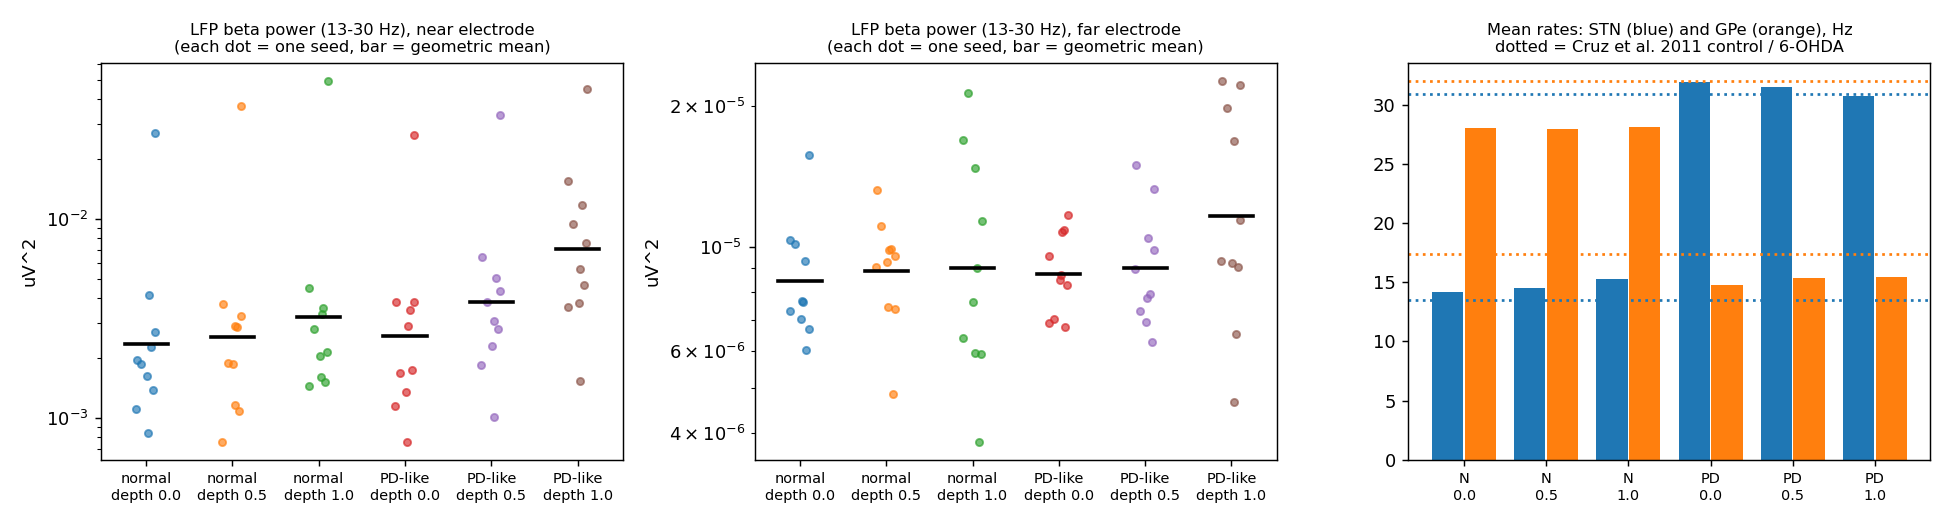


 near electrode
 cortex depth 0.5 vs flat (normal)             ratio 1.09  wilcoxon p 0.6250  sign p 0.3438  Holm p 1.0000  up in 7/10
 cortex depth 1.0 vs 0.5 (normal)              ratio 1.25  wilcoxon p 0.0645  sign p 0.0215  Holm p 0.1934  up in 9/10
 cortex depth 0.5 vs flat (PD-like)            ratio 1.48  wilcoxon p 0.0020  sign p 0.0020  Holm p 0.0156  up in 10/10
 cortex depth 1.0 vs 0.5 (PD-like)             ratio 1.86  wilcoxon p 0.0020  sign p 0.0020  Holm p 0.0156  up in 10/10
 state PD-like vs normal, flat cortex          ratio 1.10  wilcoxon p 0.5566  sign p 1.0000  Holm p 1.0000  up in 5/10
 state PD-like vs normal, depth 0.5            ratio 1.49  wilcoxon p 0.0195  sign p 0.1094  Holm p 0.0781  up in 8/10
 state PD-like vs normal, depth 1.0            ratio 2.22  wilcoxon p 0.0098  sign p 0.1094  Holm p 0.0488  up in 8/10
 interaction (state x depth 1.0 vs flat)       ratio 2.02  wilcoxon p 0.0059  sign p 0.0215  Holm p 0.0352  up in 9/10

 far electrode
 cortex depth

In [6]:
display(Image('fig_B_states_cortex.png'))
for e in ('near', 'far'):
    print('\n', e, 'electrode')
    for r in S['B'][e]:
        print(' %-45s ratio %.2f  wilcoxon p %.4f  sign p %.4f  Holm p %.4f  up in %s' % (r['name'], r['ratio'], r['wilcoxon_p'], r['sign_p'], r['holm_p'], r['wins']))

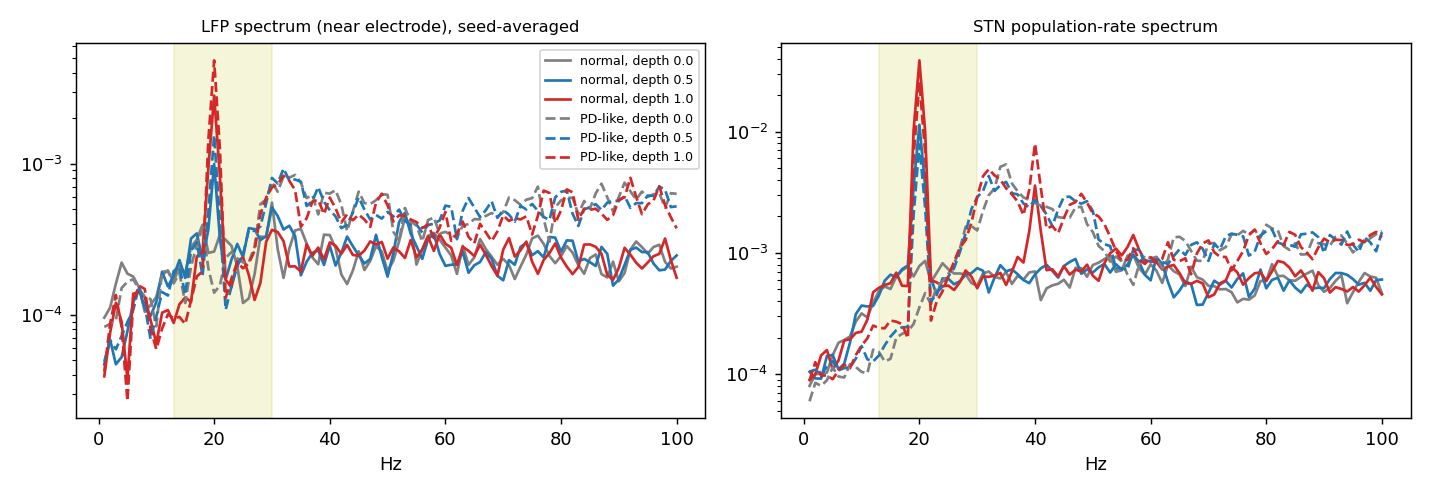

In [7]:
display(Image('fig_B_spectra.png'))

**What this shows (near electrode, 10 paired seeds, Holm over 8 comparisons per electrode)**
- With a flat cortex the Parkinson-like state has **no more LFP beta** than the normal state (×1.10, p = 0.56).
- Cortical beta depth raises LFP beta in the Parkinson-like state (×1.48 and ×1.86, Holm p = 0.016, up in 10/10 seeds) but only weakly in the normal state (×1.09, ×1.25, not significant).
- At depth 1.0 the Parkinson-like state has ×2.22 more beta (Holm p = 0.049); at depth 0.5 ×1.49 (Holm p = 0.078, not significant). The sign test for this state difference is weaker (8/10 seeds, p = 0.11).
- Interaction state × depth: ×2.02 (Holm p = 0.035).
- Far electrode (800 µm): nothing significant; amplitudes are about 1e-5.
- **Reading:** the Parkinson-like state *amplifies the LFP response to cortical beta*; it does not create beta by itself.

### 3.3 Can the loop alone make beta? (Experiment A, cortex off)

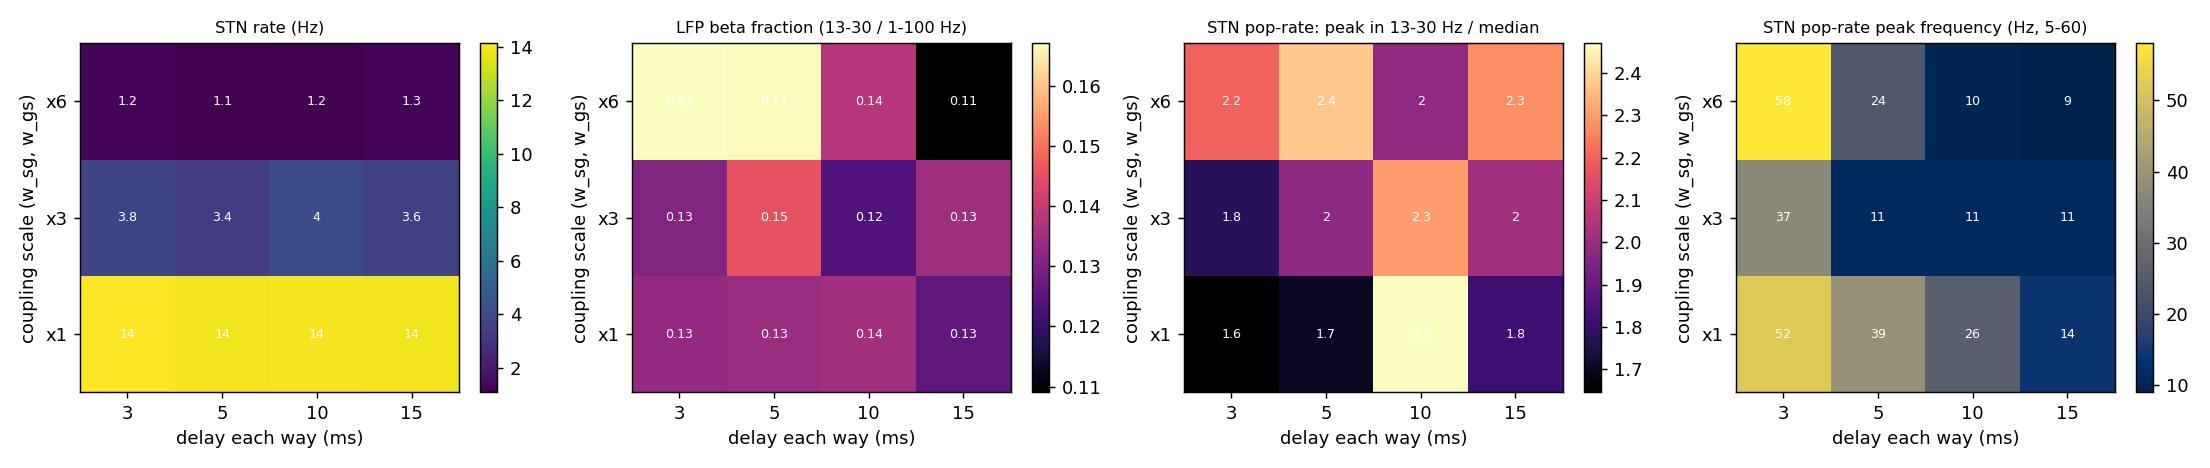

STN pop-rate peak frequency (Hz); rows = coupling x1,x3,x6; columns = delay each way 3, 5, 10, 15 ms
 x1 [52.0, 39.0, 26.0, 14.0]
 x3 [37.0, 11.0, 11.0, 11.0]
 x6 [58.0, 24.0, 10.0, 9.0]
STN rate (Hz)
 x1 [14.1, 13.8, 14.0, 13.8]
 x3 [3.8, 3.4, 4.0, 3.6]
 x6 [1.2, 1.1, 1.2, 1.3]


In [8]:
display(Image('fig_A_loop_only.png'))
print('STN pop-rate peak frequency (Hz); rows = coupling x1,x3,x6; columns = delay each way 3, 5, 10, 15 ms')
for k, row in zip((1, 3, 6), S['A']['pop_peak']): print(' x%d' % k, row)
print('STN rate (Hz)')
for k, row in zip((1, 3, 6), S['A']['stn_rate']): print(' x%d' % k, [round(x, 1) for x in row])

- At coupling ×1 the weak loop peak moves with delay: about 52, 39, 26 and 14 Hz for 3, 5, 10 and 15 ms each way. **Beta needs about 10 ms each way, longer than the 2.8 and 1.3 ms used for the states.**
- The peaks are weak (about 2–2.5 × the median power) and the LFP beta fraction stays at about 0.13 everywhere.
- Stronger coupling (×3, ×6) **silences the STN** (14 → 3.6 → 1.2 Hz) because this cell is very sensitive to inhibition, so the loop could not be strengthened further. This is a limitation.

### 3.4 The 45–60 Hz peaks (Experiment C) and the 35 Hz bump (Experiment D)

Experiment C (2 seeds): peak of seed-averaged spectra in 35-70 Hz  [frequency, peak/median]
base            STN 14.0 GPe 26.8 | STN pop [61.0, 2.3] | LFP [45.0, 2.4]
gpe_up          STN 12.2 GPe 32.9 | STN pop [44.0, 2.2] | LFP [47.0, 2.2]
gpe_down        STN 15.1 GPe 24.4 | STN pop [54.0, 3.5] | LFP [51.0, 2.3]
no_STN_to_GPe   STN 15.1 GPe 23.8 | STN pop [46.0, 3.0] | LFP [62.0, 3.0]
no_GPe_to_STN   STN 22.5 GPe 29.4 | STN pop [58.0, 1.8] | LFP [58.0, 2.7]
no_loop         STN 22.5 GPe 23.8 | STN pop [58.0, 1.8] | LFP [58.0, 2.7]



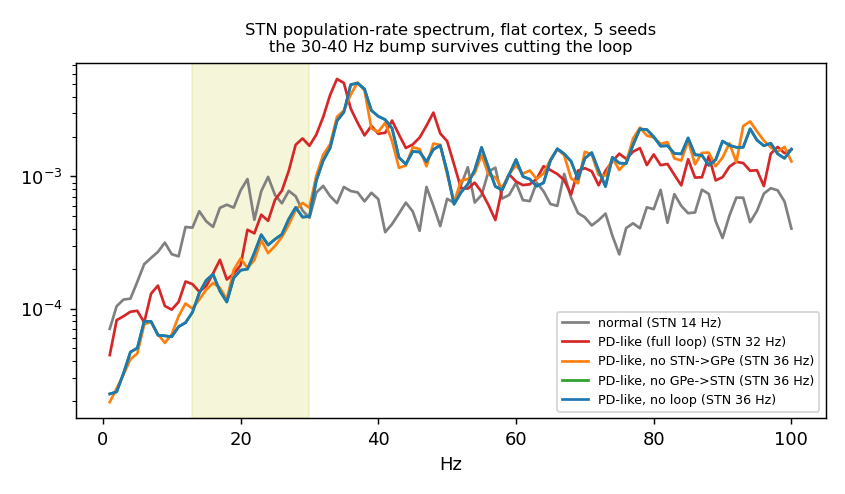

Experiment D (5 seeds, flat cortex)
normal                   STN 14.1 Hz (CV 0.38) GPe 27.5 | STN-pop peak 22-45 Hz: 24 Hz, peak/median 1.7
PD-like (full loop)      STN 31.9 Hz (CV 0.23) GPe 14.6 | STN-pop peak 22-45 Hz: 34 Hz, peak/median 5.0
PD-like, no STN->GPe     STN 35.9 Hz (CV 0.19) GPe 0.9 | STN-pop peak 22-45 Hz: 37 Hz, peak/median 4.4
PD-like, no GPe->STN     STN 36.2 Hz (CV 0.19) GPe 16.4 | STN-pop peak 22-45 Hz: 37 Hz, peak/median 4.0
PD-like, no loop         STN 36.2 Hz (CV 0.19) GPe 0.9 | STN-pop peak 22-45 Hz: 37 Hz, peak/median 4.0

Exploratory band tests, PD-like vs normal, flat cortex, 10 seeds (bands chosen after viewing the spectra):
 stn_pop_psd_13-30Hz      ratio 0.92  Holm p 0.8633  up in 5/10
 stn_pop_psd_30-40Hz      ratio 5.09  Holm p 0.0117  up in 10/10
 stn_pop_psd_40-60Hz      ratio 2.13  Holm p 0.0117  up in 10/10
 near_psd_13-30Hz         ratio 1.14  Holm p 0.8633  up in 5/10
 near_psd_30-40Hz         ratio 3.04  Holm p 0.0117  up in 10/10
 near_psd_40-60

In [9]:
print('Experiment C (2 seeds): peak of seed-averaged spectra in 35-70 Hz  [frequency, peak/median]')
for nm, v in S['C'].items():
    print('%-15s STN %.1f GPe %.1f | STN pop %s | LFP %s' % (nm, v['stn'], v['gpe'], [round(x, 1) for x in v['stn_pop_peak_35_70']], [round(x, 1) for x in v['lfp_peak_35_70']]))
print()
display(Image('fig_D_bump.png'))
print('Experiment D (5 seeds, flat cortex)')
for r in S['D']:
    print('%-24s STN %.1f Hz (CV %.2f) GPe %.1f | STN-pop peak 22-45 Hz: %d Hz, peak/median %.1f' % (r['label'], r['stn_rate'], r['stn_cv'], r['gpe_rate'], r['peak_22_45'], r['prominence']))
print('\nExploratory band tests, PD-like vs normal, flat cortex, 10 seeds (bands chosen after viewing the spectra):')
for k, v in S['B_flat_bands_exploratory'].items():
    print(' %-24s ratio %.2f  Holm p %.4f  up in %s' % (k, v['ratio'], v['holm_p'], v['wins']))

- **Experiment C:** the LFP peak between 45 and 62 Hz is not at a fixed 49 Hz and stays when both loop limbs are cut, so it is **not caused by the loop**. Its source was not identified.
- **Experiment D:** the Parkinson-like state shows 30–40 Hz power 3–5 × higher than normal (10/10 seeds). The bump **stays when the loop is cut and moves up with the STN firing rate** (peak 34 Hz at 32 Hz firing, 37 Hz at 36 Hz firing). It is the spectral signature of fast regular firing of single cells, **not a network rhythm**. Note also that with STN→GPe removed the Parkinson-like GPe nearly stops (0.9 Hz): in this model it fires only because the STN excites it.

## 4. Validation of the LFP calculation
- Line-source kernel compared with LFPy in v3: agreement to 1e-15.
- Current conservation: the sum of all membrane currents of the simulated cells should be zero at every time. NEURON does **not** include the bias-electrode current (IClamp) in `i_membrane_`, so the sum has a constant leftover equal to the injected bias, which only shifts the LFP's DC level. The v4 check therefore tests the **time-varying part** and the leftover is stored separately (`cons_dc`, `bias_sum`). Result: 1e-14 in every B run. *(In v3 the Experiment A value of 0.6–0.94 came from this same effect; B and C were 1e-14. The v3 spectra are not affected because spectra remove the mean.)*
- A single published cell and the networks without bias electrodes: 1e-14 (`checks/cons_test.py`, `checks/cons2.py`).

## 5. Limitations (state these in the report)
1. **GPe is not a published model**: a reduced one-compartment Hodgkin–Huxley point cell with T-type calcium, tuned in v3, with its rates referenced to 35 °C. In the full network its rates are about 12–15 % below the measured 32.0 / 17.4 Hz (28 and 15 Hz).
2. **The size of the Parkinson-like changes is an assumption.** Cruz et al. (2011) give the rates; Terman et al. (2002) give only the direction (more striatal-like inhibition of GPe, weaker GPe–GPe inhibition). The coupling weights STN→GPe and GPe→STN are the **same** in both states; the states differ in drive (STN bias, GPe bias) and GPe–GPe weight. The difference in rate (14 vs 32 Hz) is built in, so the amplification of cortical beta cannot be separated from the higher STN rate.
3. **No increase in bursting in the Parkinson-like state** (STN CV is lower, 0.23 vs 0.38), unlike what is reported in Parkinson's disease. No STN–STN connections, no striatal input, cortical beta is a sinusoidal modulation of Poisson input (not bursts).
4. **Dendritic 3-D shape is invented** (random branch directions); synapses are one GABA and one AMPA synapse per STN cell.
5. **Strong coupling silences the STN**, so the loop strength could not be explored beyond ×1 without balancing drive.
6. 20 STN cells; the dominant cell carries about 40 % of the near-electrode beta; far-electrode effects are not significant. Seeds change geometry, wiring and noise together.
7. Experiments A and C have only 2 seeds and are descriptive; the exploratory band tests were chosen after looking at the spectra.
8. Delays and rates were taken from two papers through a web reader and then checked by hand against the papers (Cruz et al. 2011 rates; Nevado-Holgado et al. 2014 delays).

## 6. How to re-run
Compile the mod files in `mods/` (`nrnivmodl` on Linux/macOS, `mknrndll` on Windows), keep `sth-data/` and `SThprotocell.hoc` next to `core4.py`, set `RUN_SIMS = True`. Tested on Linux with NEURON 9.0.2.

## Experiment E: is the 2x cortical-beta gain from the firing-rate drive or from the network coupling?
In experiment B the Parkinson-like state made the 20 Hz cortical input about 2x stronger in the LFP, but that state also fires faster. Here the two ingredients are crossed (10 seeds, flat cortex and depth 1.0, 40 new runs, same seeds as B):
- **drive** = `stn_bias` and `gpe_bias` (these set the firing rates), normal vs Parkinson-like
- **coupling** = `w_gg` (GPe-GPe inhibition), normal vs Parkinson-like. The STN-GPe weights were already the same in both states.

"Gain" = beta power with cortical depth 1.0 divided by beta power with flat cortex. Contrasts are paired by seed, Holm-corrected over 5 comparisons.

**Result:** the drive carries the effect (about 2.2x, Holm 0.010 and 0.023). The coupling does nothing detectable (about 0.92x, Holm 0.55). The gain follows the STN firing rate (Spearman 0.70). **Limits:** drive changes the STN and GPe biases together, so the STN part and the GPe part are not separated; only w_gg was tested as coupling; and this cannot separate firing rate itself from the cell state that sets it.

In [ ]:
exec(open('analysis_E.py').read())

cell | STN Hz | GPe Hz | beta flat | beta depth1 | gain
normal drive, normal coupling     15.3  28.1  0.00235  0.0032  x1.36  n=10
normal drive, PD coupling         13.8  32.9  0.00228  0.00286  x1.25  n=10
PD drive, normal coupling         30.9  15.0  0.00244  0.0073  x3.00  n=10
PD drive, PD coupling             30.7  15.4  0.00258  0.00708  x2.74  n=10
drive effect at normal coupling      gain ratio x2.21  p=0.002 Holm=0.010  10/10
coupling effect at normal drive      gain ratio x0.92  p=0.322 Holm=0.551  3/10
drive effect at PD coupling          gain ratio x2.19  p=0.006 Holm=0.023  9/10
coupling effect at PD drive          gain ratio x0.92  p=0.275 Holm=0.551  5/10
whole state                          gain ratio x2.02  p=0.006 Holm=0.023  9/10
Spearman gain vs STN rate SignificanceResult(statistic=np.float64(0.6959050619785752), pvalue=np.float64(6.18777814747133e-07))
